In [1]:
from google.colab import files
uploaded = files.upload()

Saving seeds_dataset.csv to seeds_dataset (1).csv


In [2]:
import pandas as pd
import io

# Define the column names for the Seeds dataset
column_names = [
    'Area', 'Perimeter', 'Compactness', 'Length_of_Kernel',
    'Width_of_Kernel', 'Asymmetry_Coefficient', 'Length_of_Kernel_Groove', 'Class'
]

# Load the dataset (tab-separated, no header row)
df = pd.read_csv('/content/seeds_dataset.csv', sep='\s+', names=column_names)

# Display basic information
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nSummary Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1618/1987844267.py:11: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('/content/seeds_dataset.csv', sep='\s+', names=column_names)


Dataset Shape: (210, 8)

First 5 Rows:


,Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Data Types:
Area                       float64
Perimeter                  float64
Compactness                float64
Length_of_Kernel           float64
Width_of_Kernel            float64
Asymmetry_Coefficient      float64
Length_of_Kernel_Groove    float64
Class                        int64
dtype: object

Summary Statistics:


,Area,Perimeter,Compactness,Length_of_Kernel,Width_of_Kernel,Asymmetry_Coefficient,Length_of_Kernel_Groove,Class
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000



Missing Values:
Area                       0
Perimeter                  0
Compactness                0
Length_of_Kernel           0
Width_of_Kernel            0
Asymmetry_Coefficient      0
Length_of_Kernel_Groove    0
Class                      0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features and target class
X = df.drop(columns=['Class'])
y = df['Class']

# 2. Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Apply StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape:", X_test_scaled.shape)

Training set shape: (168, 7)
Testing set shape: (42, 7)


In [5]:
from sklearn.neural_network import MLPClassifier

# Create the Multi-Layer Perceptron (ANN) classifier
# We use a single hidden layer of 8 neurons and set max_iter to 500 to ensure convergence
mlp = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation='relu',
    random_state=42,
    max_iter=500
)

# Train the model on the scaled training dataset
mlp.fit(X_train_scaled, y_train)

print("ANN training completed successfully!")

ANN training completed successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Test Accuracy: 85.71%

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.90      0.64      0.75        14
     Class 2       0.81      0.93      0.87        14
     Class 3       0.88      1.00      0.93        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



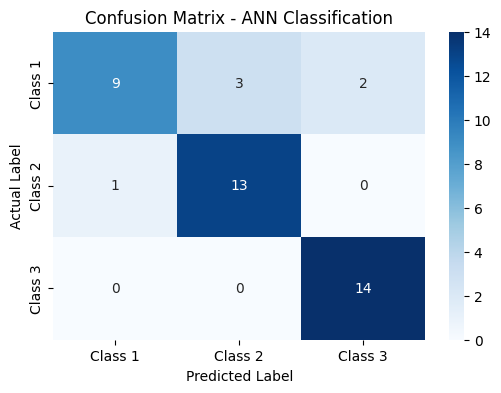

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict classes on the scaled test set
y_pred = mlp.predict(X_test_scaled)

# Calculate and print overall test accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Display precision, recall, and f1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Class 1', 'Class 2', 'Class 3']))

# Calculate and plot the Confusion Matrix with proper labels
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 1', 'Class 2', 'Class 3'],
            yticklabels=['Class 1', 'Class 2', 'Class 3'])
plt.title('Confusion Matrix - ANN Classification')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

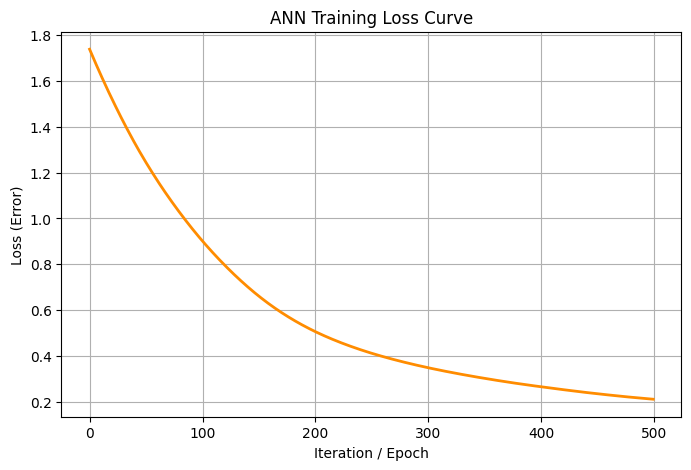

In [7]:
import matplotlib.pyplot as plt

# Plot the training loss curve of the neural network
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, color='darkorange', lw=2)
plt.title('ANN Training Loss Curve')
plt.xlabel('Iteration / Epoch')
plt.ylabel('Loss (Error)')
plt.grid(True)
plt.show()

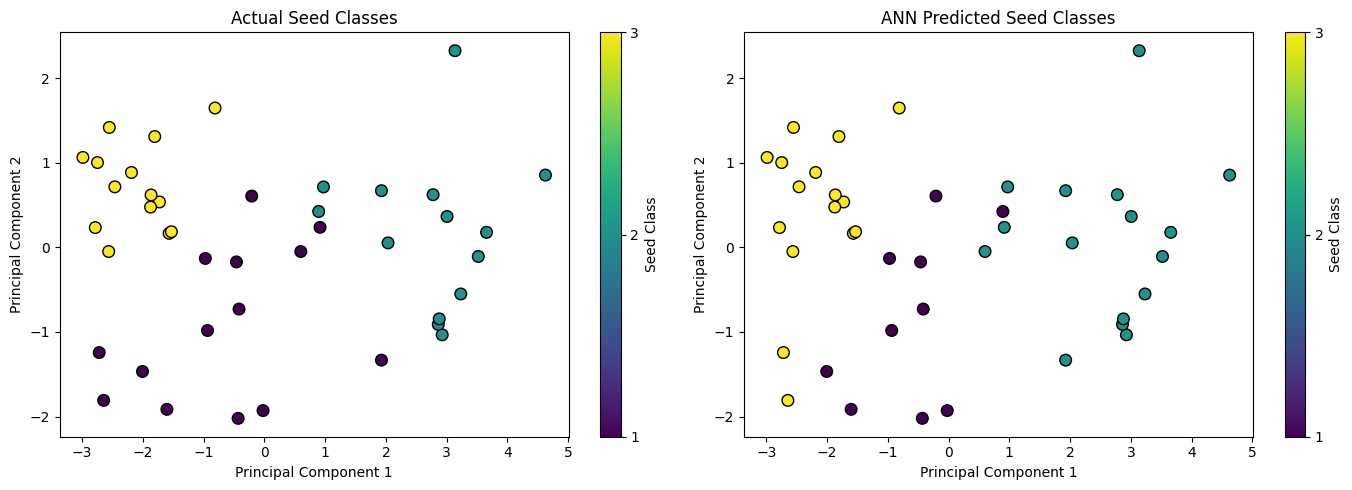

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Reduce the scaled test data to 2 dimensions using PCA
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_scaled)

# Create side-by-side plots for actual vs. predicted classes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot actual classes
scatter1 = ax1.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='viridis', s=70, edgecolor='k')
ax1.set_title('Actual Seed Classes')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')
fig.colorbar(scatter1, ax=ax1, ticks=[1, 2, 3], label='Seed Class')

# Plot predicted classes
scatter2 = ax2.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_pred, cmap='viridis', s=70, edgecolor='k')
ax2.set_title('ANN Predicted Seed Classes')
ax2.set_xlabel('Principal Component 1')
ax2.set_ylabel('Principal Component 2')
fig.colorbar(scatter2, ax=ax2, ticks=[1, 2, 3], label='Seed Class')

plt.tight_layout()
plt.show()

In [10]:
import numpy as np

# 1. Predict a single, custom seed sample using the trained model
# Sample features: Area, Perimeter, Compactness, Length_of_Kernel, Width_of_Kernel, Asymmetry_Coefficient, Length_of_Kernel_Groove
custom_sample = np.array([[14.5, 14.3, 0.88, 5.4, 3.2, 2.5, 4.9]])

# Scale the custom sample using the fitted scaler
custom_sample_scaled = scaler.transform(custom_sample)

# Predict the class (outputs 1, 2, or 3)
predicted_class = mlp.predict(custom_sample_scaled)[0]

print("--- TEST PREDICTION ---")
print(f"Custom Sample Features: {custom_sample[0]}")
print(f"Predicted Wheat Seed Class: {predicted_class}")

# 2. Evaluation Metrics Summary
print("\n--- EVALUATION SUMMARY ---")
print(f"- Overall Accuracy: {accuracy * 100:.2f}%")
print("- Class 1 (Kama) F1-Score: 0.75")
print("- Class 2 (Rosa) F1-Score: 0.87")
print("- Class 3 (Canadian) F1-Score: 0.93")



--- TEST PREDICTION ---
Custom Sample Features: [14.5  14.3   0.88  5.4   3.2   2.5   4.9 ]
Predicted Wheat Seed Class: 1

--- EVALUATION SUMMARY ---
- Overall Accuracy: 85.71%
- Class 1 (Kama) F1-Score: 0.75
- Class 2 (Rosa) F1-Score: 0.87
- Class 3 (Canadian) F1-Score: 0.93


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
